# Segmentação de imagens por cor: de RGB para HSV

**Tutorial de teoria e prática (Projeto 2, Opção 2)**

| Nome completo | RA |
|---|---|
| João Guilherme Messias de Oliveira Santos | 10426110 |
| Luis Felipe Cunha | 10419514 |

Computação Visual, Turma 201815117.000.07N, Prof. André Kishimoto.
Ciência da Computação, Faculdade de Computação e Informática, Universidade Presbiteriana Mackenzie, 2026.2.

## Sumário

1. [Motivação](#secao1)
2. [Cor e o modelo RGB](#secao2)
3. [O modelo HSV e a conversão RGB → HSV](#secao3)
4. [Validação da conversão](#secao4)
5. [Segmentação por faixa de matiz](#secao5)
6. [Comparação: a mesma segmentação em RGB](#secao6)
7. [Limitações](#secao7)
8. [Conclusão](#secao8)
9. [Uso de IA](#secao9)
10. [Referências](#secao10)

## Preparação

Bibliotecas usadas no tutorial. O NumPy guarda as imagens como matrizes, o Matplotlib mostra as imagens e os gráficos, e o Pillow lê os arquivos de imagem. A conversão de cor e a segmentação são implementadas por nós nas próximas seções.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams["figure.dpi"] = 100

<a id="secao1"></a>

## 1. Motivação

Até aqui, na disciplina, tudo foi feito em escala de cinza: no Projeto 1 convertemos a imagem para cinza antes de calcular o histograma e equalizar, e nos posts do blog trabalhamos com transformações ponto a ponto, suavização e limiarização. Na limiarização, escolhemos um valor e separamos os pixels mais claros dos mais escuros.

Agora a pergunta é outra: **como isolar um objeto pela cor dele?** Por exemplo, "quero só o objeto vermelho da foto". Para isso o cinza não serve, e vamos mostrar o motivo com uma imagem de teste.

### Imagem de teste sintética

Antes de usar fotos, criamos uma imagem pelo próprio código. Como sabemos exatamente onde cada objeto foi desenhado, temos um **gabarito**: mais à frente ele permite medir com números se uma segmentação acertou ou errou.

A cena tem:

- quatro objetos: um círculo vermelho, um quadrado verde, um círculo azul e um quadrado cinza. As cores foram escolhidas para terem **quase o mesmo tom de cinza**;
- um fundo bege claro;
- uma iluminação que escurece um pouco da esquerda para a direita;
- uma **sombra** que cobre a parte de baixo da cena e corta todos os objetos ao meio;
- um pouco de ruído, como acontece numa foto real.

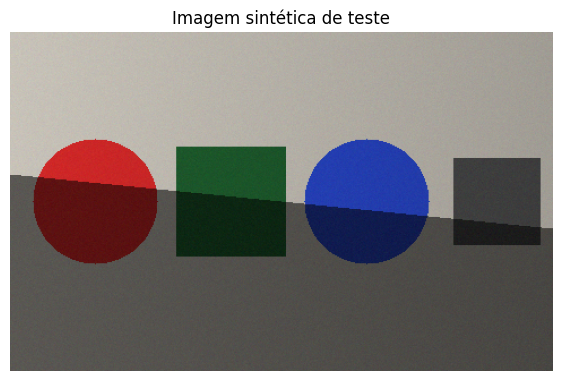

In [2]:
def cria_imagem_sintetica(altura=300, largura=480, semente=0):
    """Devolve a imagem RGB (uint8), o gabarito de cada objeto e a máscara da sombra."""
    y, x = np.mgrid[0:altura, 0:largura]

    cores = {
        "vermelho": (210, 40, 40),
        "verde": (30, 92, 45),
        "azul": (40, 70, 200),
        "cinza": (75, 75, 75),
    }
    gabarito = {
        "vermelho": (x - 75) ** 2 + (y - 150) ** 2 <= 55 ** 2,
        "verde": (np.abs(x - 195) <= 48) & (np.abs(y - 150) <= 48),
        "azul": (x - 315) ** 2 + (y - 150) ** 2 <= 55 ** 2,
        "cinza": (np.abs(x - 430) <= 38) & (np.abs(y - 150) <= 38),
    }

    img = np.empty((altura, largura, 3))
    img[:] = (200, 195, 185)
    for nome, cor in cores.items():
        img[gabarito[nome]] = cor

    # Luz e sombra multiplicam os três canais pelo mesmo fator, como acontece na prática
    sombra = y > 150 + 0.1 * (x - 240)
    fator = (1.0 - 0.2 * x / (largura - 1)) * np.where(sombra, 0.45, 1.0)
    img *= fator[..., None]

    rng = np.random.default_rng(semente)
    img += rng.normal(0, 3, img.shape)
    return np.clip(np.round(img), 0, 255).astype(np.uint8), gabarito, sombra


img_sint, gabarito, sombra = cria_imagem_sintetica()

plt.figure(figsize=(7, 4.5))
plt.imshow(img_sint)
plt.title("Imagem sintética de teste")
plt.axis("off")
plt.show()

### Tentando com a escala de cinza

Convertemos a imagem para cinza com a mesma fórmula do Projeto 1:

$$Y = 0{,}2125\,R + 0{,}7154\,G + 0{,}0721\,B$$

Depois aplicamos um limiar, como na limiarização do blog: os pixels mais escuros que 100 viram objeto.

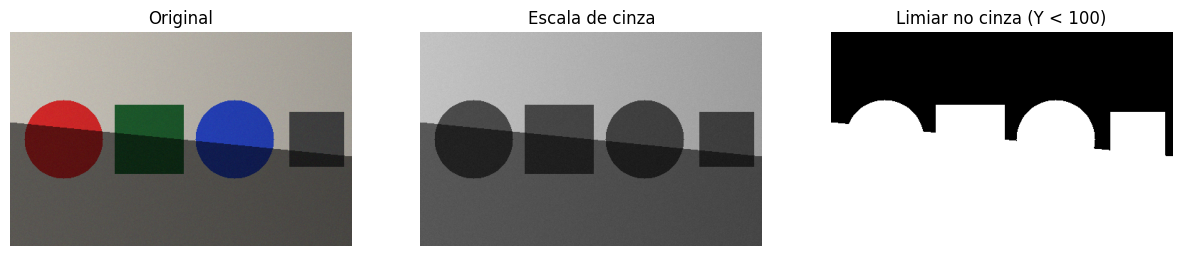

Tom de cinza médio de cada objeto (parte iluminada):
  vermelho    73.7
  verde       69.3
  azul        63.4
  cinza       61.5


In [3]:
def para_cinza(img):
    rgb = img.astype(float)
    return 0.2125 * rgb[..., 0] + 0.7154 * rgb[..., 1] + 0.0721 * rgb[..., 2]


cinza = para_cinza(img_sint)
mascara_cinza = cinza < 100

fig, eixos = plt.subplots(1, 3, figsize=(15, 3.6))
eixos[0].imshow(img_sint)
eixos[0].set_title("Original")
eixos[1].imshow(cinza, cmap="gray", vmin=0, vmax=255)
eixos[1].set_title("Escala de cinza")
eixos[2].imshow(mascara_cinza, cmap="gray")
eixos[2].set_title("Limiar no cinza (Y < 100)")
for eixo in eixos:
    eixo.axis("off")
plt.show()

print("Tom de cinza médio de cada objeto (parte iluminada):")
for nome, regiao in gabarito.items():
    print(f"  {nome:9s} {cinza[regiao & ~sombra].mean():6.1f}")

Na escala de cinza os quatro objetos têm quase o mesmo tom, entre 60 e 80. Por isso nenhum limiar consegue separar o vermelho do verde: o limiar pega todos os objetos de uma vez e ainda pega a sombra do fundo.

A informação que diferencia os objetos é a **cor**, e ela se perde quando juntamos os três canais num único número. Nas próximas seções vamos trabalhar com os três canais, primeiro em RGB e depois em HSV.

<a id="secao2"></a>

## 2. Cor e o modelo RGB

*Seção em construção.*

<a id="secao3"></a>

## 3. O modelo HSV e a conversão RGB → HSV

*Seção em construção.*

<a id="secao4"></a>

## 4. Validação da conversão

*Seção em construção.*

<a id="secao5"></a>

## 5. Segmentação por faixa de matiz

*Seção em construção.*

<a id="secao6"></a>

## 6. Comparação: a mesma segmentação em RGB

*Seção em construção.*

<a id="secao7"></a>

## 7. Limitações

*Seção em construção.*

<a id="secao8"></a>

## 8. Conclusão

*Seção em construção.*

<a id="secao9"></a>

## 9. Uso de IA

*Seção em construção.*

<a id="secao10"></a>

## 10. Referências

*Seção em construção.*